<a href="https://colab.research.google.com/github/swathi9876/breast_cancer_detection_using_decentralization/blob/main/feed_forward(non_iid).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from google.colab import files

uploaded = files.upload()

Saving ank.csv to ank.csv


In [3]:
# Install necessary libraries
!pip install torch torchvision
!pip install syft
from sklearn.preprocessing import LabelEncoder
import copy
import numpy as np
import tensorflow as tf
import pandas as pd
import io
import syft as sy
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 128.2/128.2 kB 5.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.7/129.7 kB 12.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.4/80.4 kB 7.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 903.5/903.5 kB 22.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.4/43.4 kB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 133.1/133.1 kB 12.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.6/61.6 kB 5.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 80.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 354.8/354.8 kB 28.1 MB/s eta 0:00:00



FEDAVG----Number of clients: 2
Round 1, Accuracy: 0.7944
Round 2, Accuracy: 0.8260
Round 3, Accuracy: 0.8629
Round 4, Accuracy: 0.9033
Round 5, Accuracy: 0.9069
Round 6, Accuracy: 0.9156
Round 7, Accuracy: 0.9192
Round 8, Accuracy: 0.9279
Round 9, Accuracy: 0.9297
Round 10, Accuracy: 0.9315

FEDAVG----Number of clients: 3
Round 1, Accuracy: 0.8787
Round 2, Accuracy: 0.9192
Round 3, Accuracy: 0.9315
Round 4, Accuracy: 0.9438
Round 5, Accuracy: 0.9455
Round 6, Accuracy: 0.9420
Round 7, Accuracy: 0.9490
Round 8, Accuracy: 0.9473
Round 9, Accuracy: 0.9473
Round 10, Accuracy: 0.9473

FEDAVG----Number of clients: 4
Round 1, Accuracy: 0.7241
Round 2, Accuracy: 0.7891
Round 3, Accuracy: 0.8506
Round 4, Accuracy: 0.8875
Round 5, Accuracy: 0.9121
Round 6, Accuracy: 0.9156
Round 7, Accuracy: 0.9227
Round 8, Accuracy: 0.9297
Round 9, Accuracy: 0.9332
Round 10, Accuracy: 0.9438

FEDAVG----Number of clients: 5
Round 1, Accuracy: 0.6924
Round 2, Accuracy: 0.7961
Round 3, Accuracy: 0.8629
Round 4, Ac

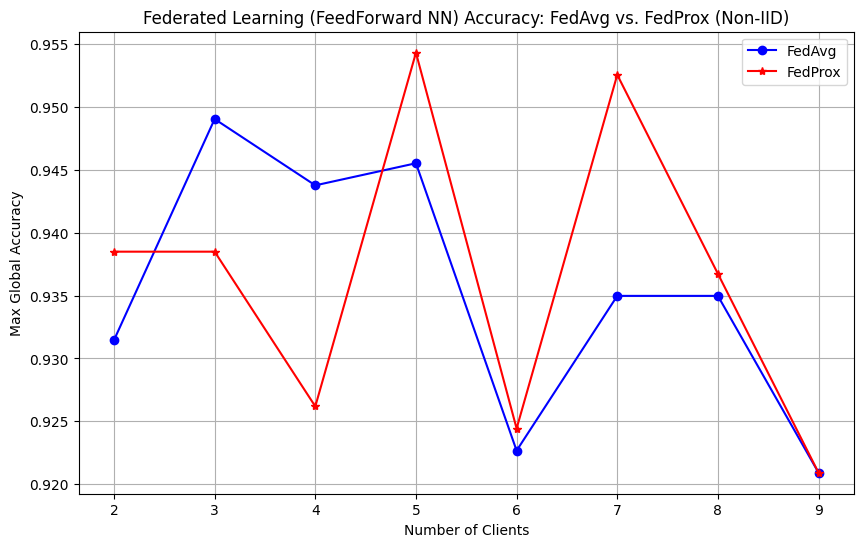

In [16]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.preprocessing import LabelEncoder, StandardScaler
import copy
import matplotlib.pyplot as plt

# Define the Feedforward Neural Network model in PyTorch
class FeedForwardNN(nn.Module):
    def __init__(self, input_dim=30, output_dim=1):
        super(FeedForwardNN, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.ReLU(),
            nn.Linear(64, output_dim),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.network(x)

# Dataset Preprocessing
def preprocess_data(data_path):
    # Load the dataset
    df = pd.read_csv(data_path)

    # Drop any rows with missing values
    df = df.dropna()

    # Label encoding for the "diagnosis" column
    label_encoder = LabelEncoder()
    df['diagnosis'] = label_encoder.fit_transform(df['diagnosis'])

    # Drop the first column (such as ID column)
    df = df.drop(df.columns[0], axis=1)

    # Extract features and labels
    X = df.iloc[:, 1:].values  # Features
    y = df.iloc[:, 0].values   # Labels (0 or 1)

    # Scale features using StandardScaler to ensure stable training and high accuracy
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    return X_scaled, y

# Split data into clients with non-IID distribution
def split_data_non_iid(X, y, num_clients, alpha=None):
    unique_classes = np.unique(y)
    class_per_client = max(1, len(unique_classes) // num_clients)

    client_data = []
    for i in range(num_clients):
        classes_for_client = unique_classes[i * class_per_client: (i + 1) * class_per_client]
        if len(classes_for_client) == 0:
            classes_for_client = unique_classes

        client_indices = []
        for cls in classes_for_client:
            cls_indices = np.where(y == cls)[0]
            # Take a shard of each class for the client
            client_indices.extend(cls_indices[:len(cls_indices) // num_clients])
        client_data.append((X[client_indices], y[client_indices]))

    return client_data

# Create a federated dataset using PyTorch Tensors
def create_federated_dataset(client_data):
    federated_data = []
    for X, y in client_data:
        federated_data.append({
            'X': torch.tensor(X, dtype=torch.float32),
            'y': torch.tensor(y, dtype=torch.float32).unsqueeze(1)
        })
    return federated_data

def federated_average(model, client_models):
    averaged_state_dict = {}
    for i, client_state_dict in enumerate(client_models):
        for key, value in client_state_dict.items():
            if i == 0:
                averaged_state_dict[key] = value.clone().detach()
            else:
                averaged_state_dict[key] += value.clone().detach()
    for key in averaged_state_dict:
        averaged_state_dict[key] /= len(client_models)
    return averaged_state_dict

def fedprox(model, client_models):
    averaged_state_dict = {}
    for i, client_state_dict in enumerate(client_models):
        for key, value in client_state_dict.items():
            if i == 0:
                averaged_state_dict[key] = value.clone().detach()
            else:
                averaged_state_dict[key] += value.clone().detach()
    for key in averaged_state_dict:
        averaged_state_dict[key] /= len(client_models)
    return averaged_state_dict

def run_feedforward_federated_simulation(algorithm_name, mu=0.01):
    num_rounds = 10
    input_dim = 30
    output_dim = 1

    # Preprocessing the dataset
    X, y = preprocess_data("ank.csv")
    X_tensor = torch.tensor(X, dtype=torch.float32)
    y_tensor = torch.tensor(y, dtype=torch.float32).unsqueeze(1)

    cl, acc = [], []
    for i in range(2, 10):
        client_data = split_data_non_iid(X, y, i, alpha=0.5)
        print(f"\n{algorithm_name.upper()}----Number of clients: {i}")
        federated_data = create_federated_dataset(client_data)
        cl.append(i)
        max_acc = 0

        model = FeedForwardNN(input_dim, output_dim)

        for round in range(num_rounds):
            client_models = []
            global_model_copy = copy.deepcopy(model)

            for client_data_batch in federated_data:
                # Avoid training if dataset is empty
                if len(client_data_batch['X']) == 0:
                    continue

                local_model = FeedForwardNN(input_dim, output_dim)
                local_model.load_state_dict(model.state_dict())
                optimizer = optim.SGD(local_model.parameters(), lr=0.01)
                criterion = nn.BCELoss()  # Correct binary loss for single sigmoid output

                # Performing local training
                for epoch in range(10):
                    optimizer.zero_grad()
                    outputs = local_model(client_data_batch['X'])
                    loss = criterion(outputs, client_data_batch['y'])

                    if algorithm_name.lower() == 'fedprox':
                        # Calculating the L2 proximal term for FedProx
                        proximal_term = 0.0
                        for local_param, global_param in zip(local_model.parameters(), global_model_copy.parameters()):
                            proximal_term += torch.sum((local_param - global_param.detach()) ** 2)
                        loss = loss + (mu / 2) * proximal_term

                    loss.backward()
                    optimizer.step()

                client_models.append(local_model.state_dict())

            # Aggregating client models
            if len(client_models) > 0:
                if algorithm_name.lower() == 'fedprox':
                    averaged_state_dict = fedprox(model, client_models)
                else:
                    averaged_state_dict = federated_average(model, client_models)
                model.load_state_dict(averaged_state_dict)

            # Calculating global accuracy
            with torch.no_grad():
                outputs = model(X_tensor)
                predicted = (outputs >= 0.5).float()
                accuracy = (predicted == y_tensor).float().mean().item()
                if accuracy > max_acc:
                    max_acc = accuracy

            print(f'Round {round+1}, Accuracy: {accuracy:.4f}')

        acc.append(max_acc)
    return cl, acc

def main():
    # Running both simulations sequentially using feedforward design
    cl_avg, acc_avg = run_feedforward_federated_simulation('fedavg')
    cl_prox, acc_prox = run_feedforward_federated_simulation('fedprox', mu=0.01)

    # Plotting unified results
    plt.figure(figsize=(10, 6))
    plt.plot(cl_avg, acc_avg, marker='o', label='FedAvg', color='blue')
    plt.plot(cl_prox, acc_prox, marker='*', label='FedProx', color='red')
    plt.xlabel('Number of Clients')
    plt.ylabel('Max Global Accuracy')
    plt.title('Federated Learning (FeedForward NN) Accuracy: FedAvg vs. FedProx (Non-IID)')
    plt.legend()
    plt.grid(True)
    plt.show()

if __name__ == "__main__":
    main()